In [1]:
import pandas as pd
from sklearn.manifold import TSNE
import plotly.express as px
import matplotlib.colors as mcolors
import re
from Bio import Phylo
import matplotlib.pyplot as plt

### Load Data

- Distance matrix of maximum likelihood distances calculated by iqtree2
- Metadata

In [2]:
mat = pd.read_csv('data/cox2_th_test/cox2_th_test-qiime-msa-mds-dist.mldist', sep=' ', index_col=0, header=None)
mat.columns = mat.index
mat

,KM819519.1,LC028397.1,MN381730.1,KP723171.1,GU071804.1,GU071754.1,GU071755.1,GU071756.1,GU071757.1,GU071758.1,...,MN116745.1,MN116746.1,GU360982.1,GU360992.1,GU361008.1,MK602199.1,MK602203.1,MK602204.1,MK602213.1,KP420744.1
0,,,,,,,,,,,,,,,,,,,,,
KM819519.1,0.000000,0.039474,0.044835,0.108612,0.044600,0.032686,0.025254,0.041608,0.041361,0.025057,...,0.169169,0.187346,0.343731,0.298225,0.307959,0.043523,0.048300,0.048937,0.061409,0.910291
LC028397.1,0.039474,0.000000,0.048886,0.107035,0.043856,0.045053,0.032938,0.059202,0.058833,0.036986,...,0.152801,0.184011,0.367957,0.292838,0.302420,0.036182,0.036140,0.030564,0.041789,0.844987
MN381730.1,0.044835,0.048886,0.000000,0.124661,0.035763,0.032903,0.003361,0.025254,0.033159,0.025220,...,0.199672,0.158199,0.309863,0.362309,0.373254,0.004825,0.025327,0.019998,0.036825,0.879869
KP723171.1,0.108612,0.107035,0.124661,0.000000,0.123565,0.119731,0.110227,0.121685,0.120820,0.109217,...,0.159635,0.175224,0.348850,0.320127,0.317949,0.107032,0.114770,0.106692,0.112695,0.878838
GU071804.1,0.044600,0.043856,0.035763,0.123565,0.000000,0.043762,0.024666,0.049282,0.048988,0.032297,...,0.165702,0.167665,0.293300,0.289711,0.299290,0.024956,0.009571,0.014405,0.030249,0.892486
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MK602199.1,0.043523,0.036182,0.004825,0.107032,0.024956,0.042689,0.004825,0.037394,0.049564,0.037324,...,0.203865,0.161163,0.334072,0.348679,0.376503,0.000000,0.025067,0.019795,0.036428,0.867479
MK602203.1,0.048300,0.036140,0.025327,0.114770,0.009571,0.040682,0.025327,0.054786,0.061416,0.030406,...,0.165239,0.154785,0.296314,0.288661,0.313140,0.025067,0.000000,0.014464,0.030388,0.853311
MK602204.1,0.048937,0.030564,0.019998,0.106692,0.014405,0.041189,0.019998,0.055522,0.055037,0.030784,...,0.180093,0.181797,0.311418,0.292979,0.317776,0.019795,0.014464,0.000000,0.024992,0.809859


In [3]:
df = pd.read_csv('data/cox2_th_test/cox2_th_test-meta.tsv', index_col='accession', sep='\t')
merged = df[df.index.isin(mat.index)]
merged

,creation_date,title,authors,sequence_length,organism_name,tax_id_x,cox2_start,cox2_end,cox2_strand,organism_name_sanitized,...,trimed_seq_len,tax_id_y,species,domain,kingdom,phylum,class,order,family,genus
accession,,,,,,,,,,,,,,,,,,,,,
KM819519.1,27-JAN-2015,Pythiogeton ramosum isolate SC2.7.2 cytochrome...,"Le,D.P., Smith,M.K. and Aitken,E.",614,Pythiogeton ramosum,1217586,<0,>614,1.0,Pythiogeton ramosum,...,307,1217586.0,Pythiogeton ramosum,Eukaryota,Sar,Stramenopiles,Oomycota,Pythiales,Pythiogetonaceae,Pythiogeton
LC028397.1,01-NOV-2016,Pythium barbulae mitochondrial cox2 gene for c...,"Ueta,S. and Tojo,M.",613,Globisporangium barbulae,1629122,<0,>613,1.0,Globisporangium barbulae,...,306,1629122.0,Globisporangium barbulae,Eukaryota,Sar,Stramenopiles,Oomycota,Pythiales,Pythiaceae,Globisporangium
MN381730.1,15-APR-2020,Globisporangium spinosum strain SQ00903-1 cyto...,"Huo,C., Zhao,Z. and Cao,J.",604,Globisporangium spinosum,2125998,<0,>604,1.0,Globisporangium spinosum,...,303,2125998.0,Globisporangium spinosum,Eukaryota,Sar,Stramenopiles,Oomycota,Pythiales,Pythiaceae,Globisporangium
KP723171.1,16-SEP-2015,Globisporangium kandovanense voucher CCTU 1813...,"Chenari Bouket,A., Arzanlou,M., Tojo,M. and Ba...",587,Globisporangium kandovanense,1632203,24,>587,1.0,Globisporangium kandovanense,...,301,1632203.0,Globisporangium kandovanense,Eukaryota,Sar,Stramenopiles,Oomycota,Pythiales,Pythiaceae,Globisporangium
GU071804.1,25-JUL-2016,Pythium irregulare strain STE-U6769 cytochrome...,"Spies,C.F., Mazzola,M., Botha,W.J., Langenhove...",596,Globisporangium irregulare,36331,<0,>596,1.0,Globisporangium irregulare,...,299,36331.0,Globisporangium irregulare,Eukaryota,Sar,Stramenopiles,Oomycota,Pythiales,Pythiaceae,Globisporangium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MK602199.1,29-APR-2020,Globisporangium spinosum isolate C9 cytochrome...,"Ibanez,J.M., Obregon,V.G. and Favaro,M.A.",518,Globisporangium spinosum,2125998,<0,>518,1.0,Globisporangium spinosum,...,211,2125998.0,Globisporangium spinosum,Eukaryota,Sar,Stramenopiles,Oomycota,Pythiales,Pythiaceae,Globisporangium
MK602203.1,29-APR-2020,Globisporangium irregulare isolate C13 cytochr...,"Ibanez,J.M., Obregon,V.G. and Favaro,M.A.",518,Globisporangium irregulare,36331,<0,>518,1.0,Globisporangium irregulare,...,211,36331.0,Globisporangium irregulare,Eukaryota,Sar,Stramenopiles,Oomycota,Pythiales,Pythiaceae,Globisporangium
MK602204.1,29-APR-2020,Globisporangium irregulare isolate C14 cytochr...,"Ibanez,J.M., Obregon,V.G. and Favaro,M.A.",518,Globisporangium irregulare,36331,<0,>518,1.0,Globisporangium irregulare,...,211,36331.0,Globisporangium irregulare,Eukaryota,Sar,Stramenopiles,Oomycota,Pythiales,Pythiaceae,Globisporangium


### t-SNE Plot

In [4]:
tsne = TSNE(metric='precomputed', perplexity=30,  init='random', random_state=42)
coords = tsne.fit_transform(mat.to_numpy())

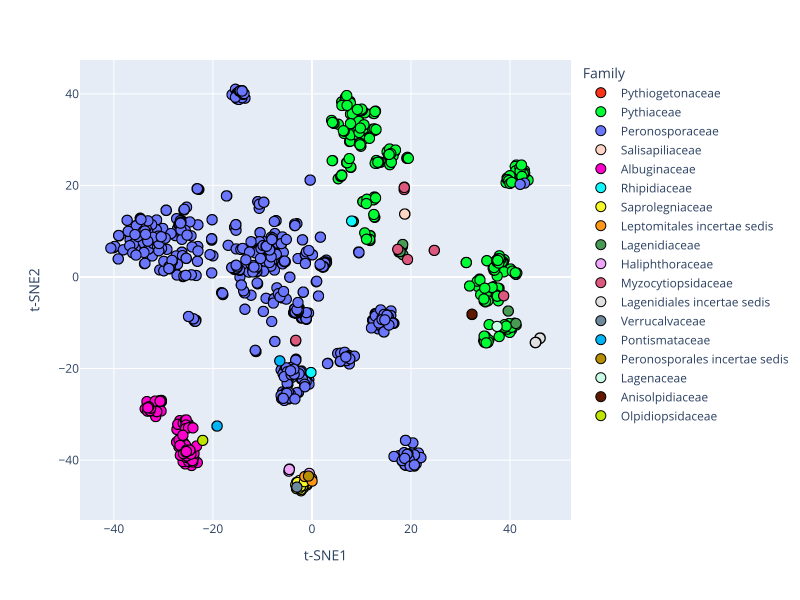

In [5]:
# DataFrame for plotting
df_plot = pd.DataFrame({
    'Accession': merged.index,
    'Family': merged['family'],
    'Species': merged['organism_name_sanitized'],
    't-SNE1': coords[:, 0],
    't-SNE2': coords[:, 1]
})

# Custom colors
unique_families = df_plot['Family'].unique()
palette = px.colors.qualitative.Light24[:len(unique_families)]
hex_colors = [mcolors.to_hex(color) for color in palette]
color_discrete_map = {family: hex_colors[i] for i, family in enumerate(unique_families)}
color_discrete_map['Lagenidiales incertae sedis'] = '#E0E0E0'
color_discrete_map['Anisolpidiaceae'] = '#611800'
color_discrete_map['Olpidiopsidaceae'] = '#BDE500'


# Plot
fig = px.scatter(
    df_plot,
    x='t-SNE1',
    y='t-SNE2',
    color='Family',
    hover_name='Accession',
    hover_data={'Species': True, 't-SNE1': False, 't-SNE2': False},
    title=None,
    color_discrete_map=color_discrete_map,
    width=800,
    height=600,
)

fig.update_traces(marker=dict(size=10, line=dict(width=1, color='black')))
fig.update_layout(legend_title_text='Family')

fig.show(renderer="svg")
fig.write_image("tsne.svg", format='svg')

#py.plot(fig, filename='tsne.svg')

In [6]:
tsne_cols = pd.DataFrame(list(color_discrete_map.items()), columns=['family', 'color'])
tsne_cols.to_csv('family_color_map.tsv', sep='\t', index=False)

### Tree

In [7]:
# iqtree2 -s data/cox2_th_test/cox2_th_test-qiime-msa.fa -T AUTO -B 1000
# Load mapping
mapping = pd.read_csv("data/cox2_th_test/cox2_th_test-meta.tsv", sep='\t')

# Load Newick file as text
with open("data/cox2_th_test/cox2_th_test-qiime-msa.fa.treefile") as f:
    tree_text = f.read()

# Replace each accession with the species name
for _, row in mapping.iterrows():
    # Replace whole accession with species name (with underscores, to be Newick-safe)
    safe_species = row['species'].replace(" ", "_")
    replacement = f'{safe_species}_{row['accession']}'
    tree_text = re.sub(rf'\b{re.escape(row['accession'])}\b', replacement, tree_text)

# Save updated tree
with open("nj_tree_replace.nwk", "w") as f:
    f.write(tree_text)



<Figure size 640x480 with 0 Axes>

In [8]:
tree = Phylo.read("nj_tree_replace.nwk", "newick")

fig = plt.figure(figsize=(20, 300))
axes = fig.add_subplot(1, 1, 1)

Phylo.draw(tree, axes=axes)
#Phylo.write(tree, "tree.svg", "svg")
#plt.tight_layout()  # Helps reduce overlapping
#plt.show()
plt.savefig('tree.svg', dpi=700)